# Niskala – Preprocessing and Forecast Modeling

This notebook builds a one-month-ahead hotspot forecast for each district in West Kalimantan and checks whether it beats simple baselines.
All choices follow the EDA (`eda.ipynb`, summary in `EDA.md`).

**Models compared**
- **Climatology:** the median of the same month in past years (descriptive statistics).
- **Persistence:** next month equals this month.
- **Negative Binomial regression:** the main model.
- **LSTM:** a small neural network, kept as an experiment.

Run steps 1–3 of the pipeline first.

In [1]:
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

sys.path.insert(0, str(Path.cwd().parent / "pipeline"))
import forecast_lib as fl
import learning_curves as lc
from config import SPARSE_DISTRICTS, PROVINCE

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})
COLORS = {"climatology": "#898781", "persistence": "#e8a33b", "nb": "#2a78d6", "lstm": "#1baf7a", "actual": "#0b0b0b"}
pd.set_option("display.width", 140)

P, enso = fl.load()
print(f"{len(P)} months, {P.shape[1]} districts, {P.index.min()} to {P.index.max()}")

292 months, 14 districts, 200207 to 202610


## 1. Preprocessing

Each row is one district in one target month. Every input is something we would already know at the start of that month.

| Feature | Meaning |
|:---|:---|
| `clim_mean`, `offset` | Normal level for this district and month (from training years only) |
| `anom_l1`, `anom_l2` | How far the last 1 and 2 months were above or below normal (log scale) |
| `enso_l1` | Niño 3.4 one month earlier |
| `dry` | 1 for June–October |
| `thr` | Count above which the month counts as "above normal" (1.5× normal) |

Two rules keep the test honest:
- The "normal" is recomputed from the training period only, every time we train.
- Kota Pontianak and Kota Singkawang are too sparse to model. They enter the province total with their climatology.

In [2]:
clim = fl.climatology(P, 202012)
modeled = [d for d in P.columns if d not in SPARSE_DISTRICTS]
table = fl.features(P, enso, clim, [ym for ym in P.index if ym <= 202012], modeled)
print(f"Training rows: {len(table)}  ({len(modeled)} districts)")
table[["ym", "district", "y", "clim_median", "clim_mean", "anom_l1", "anom_l2", "enso_l1", "dry", "thr"]].sample(6, random_state=1).round(2)

Training rows: 2628  (12 districts)


,ym,district,y,clim_median,clim_mean,anom_l1,anom_l2,enso_l1,dry,thr
28,200212,Kubu Raya,0.00,1.00,9.48,-1.18,-3.35,1.20,0,16.72
876,200811,Bengkayang,51.89,0.00,6.24,0.14,0.54,-0.27,0,11.86
2533,202005,Kapuas Hulu,1.00,4.20,12.72,-0.10,-1.37,0.66,0,21.57
367,200504,Mempawah,14.11,8.03,43.14,0.55,1.83,0.55,0,67.21
1114,201006,Sekadau,0.00,2.00,5.67,-0.86,-0.17,0.00,1,11.00
1408,201207,Kubu Raya,306.50,162.00,425.13,2.21,2.06,0.05,1,640.20


## 2. Choosing the model setup on validation data

We train on 2003–2018 and compare options on 2019–2020. The test years (2021 onward) are not used for these choices.

We compare ENSO at lag 1 vs lag 1 and 2, and the mean vs the median as the point forecast.

In [3]:
clim_v = fl.climatology(P, 201812)
tr = fl.features(P, enso, clim_v, [ym for ym in P.index if ym <= 201812], modeled)
va = fl.features(P, enso, clim_v, [ym for ym in P.index if 201901 <= ym <= 202012], modeled)

def design(df, terms):
    X = pd.DataFrame({"const": 1.0, "dry": df.dry, "enso_l1_dry": df.enso_l1 * df.dry, "enso_l2_dry": df.enso_l2 * df.dry,
                      "anom_l1": df.anom_l1, "anom_l2": df.anom_l2, "anom_l1_dry": df.anom_l1 * df.dry})
    return X[terms]

options = {
    "ENSO lags 1 and 2": ["const", "dry", "enso_l1_dry", "enso_l2_dry", "anom_l1", "anom_l2", "anom_l1_dry"],
    "ENSO lag 1": ["const", "dry", "enso_l1_dry", "anom_l1", "anom_l2", "anom_l1_dry"],
}
obs = (va.y > va.thr).astype(float)
rows = []
for name, terms in options.items():
    res = sm.NegativeBinomial(np.round(tr.y).astype(int), design(tr, terms), offset=tr.offset).fit(disp=0, maxiter=300)
    mu = np.asarray(res.predict(design(va, terms), offset=va.offset))
    n = 1 / res.params["alpha"]
    p = n / (n + mu)
    rows.append({"setup": f"NB, {name}", "MAE (mean)": np.abs(mu - va.y).mean(), "MAE (median)": np.abs(stats.nbinom.ppf(0.5, n, p) - va.y).mean(),
                 "Brier": ((stats.nbinom.sf(np.floor(va.thr.clip(lower=0)), n, p) - obs) ** 2).mean(),
                 "ENSO coefficients": res.params.filter(like="enso").round(2).to_dict()})
for name, col in [("Climatology", "clim_median"), ("Persistence", "persistence")]:
    rows.append({"setup": name, "MAE (median)": np.abs(va[col] - va.y).mean()})
pd.DataFrame(rows).round(3)

,setup,MAE (mean),MAE (median),Brier,ENSO coefficients
0,"NB, ENSO lags 1 and 2",143.154,137.066,0.078,"{'enso_l1_dry': 0.45, 'enso_l2_dry': -0.54}"
1,"NB, ENSO lag 1",144.357,132.309,0.079,{'enso_l1_dry': 0.01}
2,Climatology,NaN,151.224,NaN,NaN
3,Persistence,NaN,243.691,NaN,NaN


**Takeaways**
- Using the median as the point forecast lowers the error, because the counts are very skewed.
- With both ENSO lags, the two coefficients cancel each other out (the lags are almost the same series). One lag is simpler and just as good.
- Chosen setup: **NB with ENSO at lag 1, median as the point forecast.**

## 3. LSTM learning curves

The first LSTM (12-month window, 16 units, district identity as input) overfit quickly. Following the EDA, the new one uses a 3-month window, 8 units, stronger regularization, and no district identity.

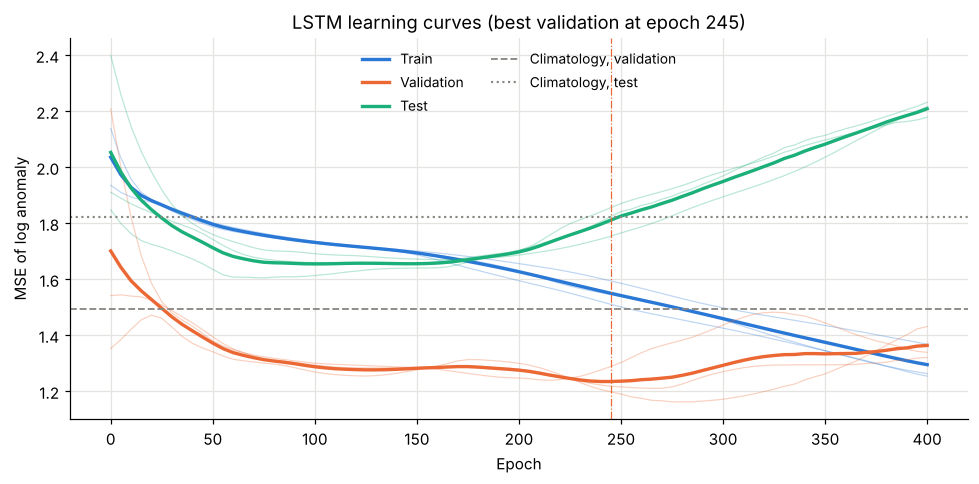

In [4]:
curves, base = lc.curves()
lc.plot(curves, base);

**Takeaways**
- Validation error reaches its lowest point around epoch 250 and then rises: after that the model starts to memorize.
- Test error is lowest earlier (epochs 100–175) and is then clearly below climatology. At the epoch picked by validation it is only about equal to climatology.
- So the smaller LSTM learns something, but the best stopping point is not stable from one period to another.

## 4. Test 1: train up to 2020, test on 2021–2025

These five years include quiet La Niña years (2021–2022) and an El Niño year (2023).

- **MAE:** average error in hotspots per district-month (lower is better).
- **log MAE:** the same on a log scale, so small and large districts count more equally.
- **Brier:** accuracy of the probability that a month is above normal (0 is perfect; lower is better).

In [5]:
stage_a = fl.run_stage(P, enso, 202012, [ym for ym in P.index if 202101 <= ym <= 202512])
score_a = fl.evaluate(stage_a[0], stage_a[1]).drop(index="clim_mean").rename(index={"clim_median": "climatology"})
score_a.round(3)

,mae,rmse,mae_fire_season,log_mae,province_mae,brier_above_normal
climatology,132.275,387.244,360.576,1.151,1317.052,0.148
persistence,132.169,326.549,343.488,1.253,1402.467,NaN
nb,87.422,226.966,227.554,0.985,856.344,0.135
lstm,148.185,447.197,410.019,0.996,1633.397,0.138


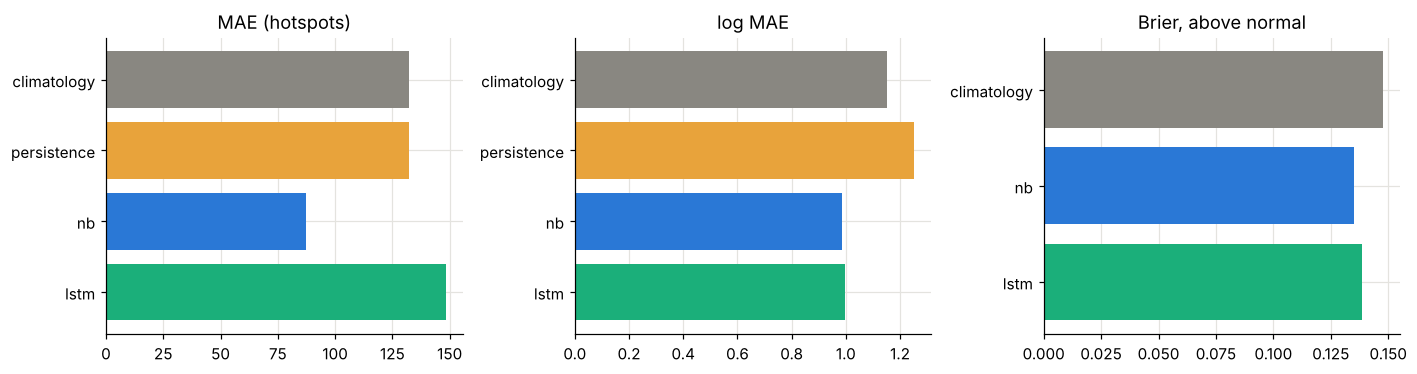

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col, title in zip(axs, ["mae", "log_mae", "brier_above_normal"], ["MAE (hotspots)", "log MAE", "Brier, above normal"]):
    s = score_a[col].dropna()
    ax.barh(s.index, s.values, color=[COLORS[m] for m in s.index])
    ax.set_title(title)
    ax.invert_yaxis()
plt.tight_layout()

**Takeaways**
- The Negative Binomial model has the lowest error on every measure. Its MAE is about a third lower than climatology and persistence.
- The LSTM beats climatology on log MAE and Brier, but not the NB model.
- The NB probability of "above normal" is more accurate (lower Brier score) than the historical frequency.
- The NB 10–90% range contains 92% of the actual values (the target is 80%), so it is slightly cautious.

## 5. Test 2: train up to 2025, test on January–October 2026

2026 is one of the most extreme fire seasons on record, so this is a hard test.

In [7]:
stage_b = fl.run_stage(P, enso, 202512, [ym for ym in P.index if 202601 <= ym <= 202610])
score_b = fl.evaluate(stage_b[0], stage_b[1]).drop(index="clim_mean").rename(index={"clim_median": "climatology"})
score_b.round(3)

,mae,rmse,mae_fire_season,log_mae,province_mae,brier_above_normal
climatology,512.323,2005.999,1211.049,1.230,5822.119,0.267
persistence,587.817,1728.977,1362.000,1.725,6897.600,NaN
nb,497.550,1935.679,1174.938,1.090,5753.180,0.237
lstm,510.295,2004.144,1208.948,1.096,5813.616,0.250


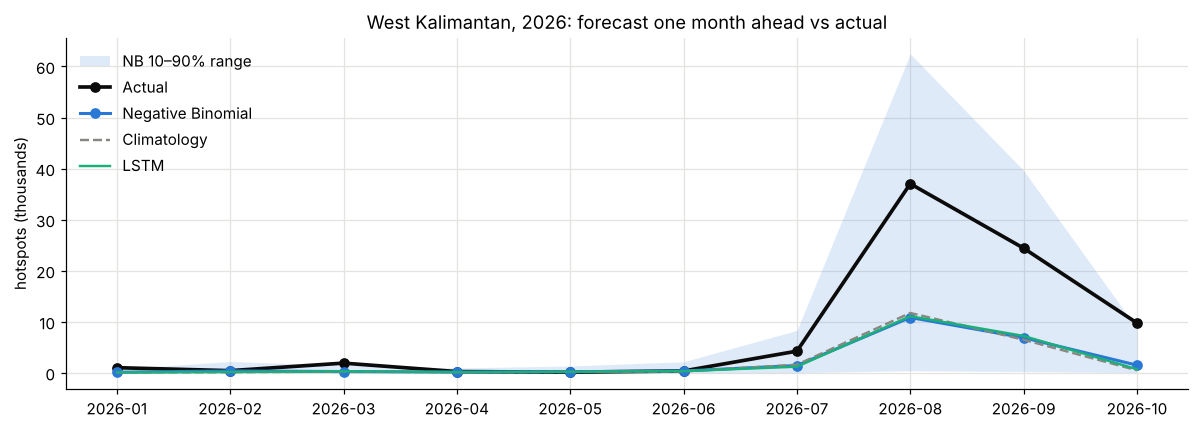

In [8]:
t, s = stage_b[0], stage_b[1]
prov = t.groupby("ym")[["y", "clim_median", "nb", "nb_low", "nb_high", "lstm"]].sum()
prov[["y", "clim_median", "nb", "nb_low", "nb_high", "lstm"]] += s.groupby("ym")[["y", "clim_median", "clim_median", "clim_median", "clim_median", "clim_median"]].sum().to_numpy()
x = [f"{m // 100}-{m % 100:02d}" for m in prov.index]
fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(x, prov.nb_low / 1000, prov.nb_high / 1000, color=COLORS["nb"], alpha=0.15, lw=0, label="NB 10–90% range")
ax.plot(x, prov.y / 1000, color=COLORS["actual"], lw=2.4, marker="o", label="Actual")
ax.plot(x, prov.nb / 1000, color=COLORS["nb"], lw=2, marker="o", label="Negative Binomial")
ax.plot(x, prov.clim_median / 1000, color=COLORS["climatology"], lw=1.6, ls="--", label="Climatology")
ax.plot(x, prov.lstm / 1000, color=COLORS["lstm"], lw=1.6, label="LSTM")
ax.set(ylabel="hotspots (thousands)", title="West Kalimantan, 2026: forecast one month ahead vs actual")
ax.legend(frameon=False)
plt.tight_layout()

In [9]:
cols = ["ym", "district", "y", "clim_median", "nb", "nb_low", "nb_high", "p_above_clim", "p_above_nb"]
t[t.district.isin(["Ketapang", "Kayong Utara"]) & t.month.isin([7, 8, 9, 10])][cols].rename(columns={
    "y": "actual", "clim_median": "climatology", "p_above_clim": "P(above) history", "p_above_nb": "P(above) NB"}).round(2)

,ym,district,actual,climatology,nb,nb_low,nb_high,P(above) history,P(above) NB
74,202607,Kayong Utara,569.0,34.30,35.0,1.0,201.0,0.25,0.24
75,202607,Ketapang,968.0,212.00,185.0,7.0,1070.0,0.29,0.22
86,202608,Kayong Utara,3111.0,300.93,420.0,16.0,2423.0,0.25,0.41
87,202608,Ketapang,15880.0,2811.20,2749.0,104.0,15851.0,0.17,0.31
98,202609,Kayong Utara,2683.0,270.50,646.0,24.0,3729.0,0.17,0.46
99,202609,Ketapang,16675.0,2776.37,3500.0,132.0,20182.0,0.21,0.37
110,202610,Kayong Utara,59.0,7.56,113.0,4.0,653.0,0.21,0.43
111,202610,Ketapang,9289.0,274.50,1030.0,39.0,5942.0,0.21,0.37


**Takeaways**
- Every model underestimates the size of the 2026 peak. A one-month forecast cannot see a season this extreme coming from the past alone.
- The NB model still helps where it matters: its probability of an above-normal month is clearly higher than the historical rate (for example Kayong Utara in September: 46% vs 17%), and it has the best Brier score.
- The NB 10–90% range still contains 82% of the actual district values in 2026 (90% in July–October). For BPBD, the range and the probability are more useful than the single number.

## 6. What the NB model learned

Effects are shown as multipliers on the expected hotspots (1.00 = no effect). The model is trained on all data through October 2026.

In [10]:
stage_c = fl.run_stage(P, enso, 202610, [202611])
effects = np.exp(stage_c[2].params.drop(["const", "alpha"]))
pd.DataFrame({"multiplier": effects.round(3), "meaning": [
    "June–October vs the rest of the year (beyond the normal level)",
    "+1 °C Niño 3.4 last month, in the dry season",
    "Last month was one log unit above normal",
    "Two months ago was one log unit above normal",
    "Extra effect of last month's anomaly in the dry season"]})

,multiplier,meaning
dry,1.019,June–October vs the rest of the year (beyond t...
enso_l1_dry,1.050,"+1 °C Niño 3.4 last month, in the dry season"
anom_l1,1.190,Last month was one log unit above normal
anom_l2,1.098,Two months ago was one log unit above normal
anom_l1_dry,1.076,Extra effect of last month's anomaly in the dr...


**Takeaways**
- Recent fire activity is the strongest signal: a month above normal raises the next month's expected hotspots, more so in the dry season.
- Once last month's activity is in the model, ENSO adds little. The drought that ENSO causes is already visible in the fires themselves.

## 7. Forecast for November 2026

In [11]:
fc = stage_c[0][["district", "clim_median", "persistence", "nb", "nb_low", "nb_high", "p_above_nb", "lstm"]]
fc.rename(columns={"clim_median": "climatology", "nb": "NB forecast", "nb_low": "NB low (10%)", "nb_high": "NB high (90%)",
                   "p_above_nb": "P(above normal)"}).sort_values("NB forecast", ascending=False).round(2).reset_index(drop=True)

,district,climatology,persistence,NB forecast,NB low (10%),NB high (90%),P(above normal),lstm
0,Ketapang,17.28,9289.0,131.0,5.0,740.0,0.36,45.96
1,Sambas,0.00,4.0,5.0,0.0,29.0,0.16,1.61
2,Sanggau,5.01,64.0,3.0,0.0,20.0,0.18,3.90
3,Sintang,4.50,168.0,3.0,0.0,21.0,0.20,4.19
4,Landak,2.50,22.0,2.0,0.0,15.0,0.14,2.07
5,Kapuas Hulu,0.50,14.0,2.0,0.0,10.0,0.16,1.36
6,Bengkayang,1.00,7.0,2.0,0.0,12.0,0.12,1.17
7,Kubu Raya,2.50,7.0,2.0,0.0,14.0,0.16,2.60
8,Melawi,3.00,99.0,2.0,0.0,15.0,0.24,2.85
9,Kayong Utara,0.00,59.0,1.0,0.0,9.0,0.21,1.91


## 8. Summary

| | Result |
|:---|:---|
| Main model | Negative Binomial regression |
| 2021–2025 test | Lowest error on every measure; MAE about a third lower than climatology and persistence |
| 2026 test | All models miss the size of the extreme peak; NB gives the best probabilities and a range that covers most values |
| LSTM | Learns something after the EDA-based redesign, but stays behind the NB model on this small dataset |
| What to show BPBD | The NB forecast, its 10–90% range, and the probability of an above-normal month |

Results are exported to `data/web/forecast.json` by `python run_pipeline.py 6`.